# English → Telugu Neural Machine Translation
**From-scratch GRU + Bahdanau Attention vs. pretrained NLLB-200**

Run in Google Colab with a GPU runtime. This notebook streams the Telugu (`te`) configuration of AI4Bharat Samanantar, keeps a bounded sample, trains a compact educational model, and evaluates NLLB-200 on the same held-out examples.

> Practical scope: start with 20,000 training pairs for a quick pipeline check. Increase `MAX_PAIRS` only after confirming runtime and GPU memory. This is a project-scale experiment, not a production translation system.

## 1. Runtime and dependencies

In [1]:
!pip -q install datasets sacrebleu transformers sentencepiece accelerate matplotlib seaborn

In [2]:
import os, re, math, random, json, time
from collections import Counter
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
import sacrebleu
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda
Tesla T4


## 2. Stream a bounded Telugu subset
The Hugging Face dataset card documents the `te` configuration and `src`/`tgt` fields. Streaming avoids downloading the full Telugu corpus. We stop after collecting the configured number of usable pairs.

In [3]:
MAX_PAIRS = 30000       # start at 20k-30k; increase later if time permits
MAX_LEN = 24             # word-level model sequence limit
MIN_FREQ = 2

stream = load_dataset("ai4bharat/samanantar", "te", split="train", streaming=True)
pairs = []
for row in stream:
    src, tgt = str(row["src"]).strip(), str(row["tgt"]).strip()
    if src and tgt and len(src.split()) <= MAX_LEN and len(tgt.split()) <= MAX_LEN:
        pairs.append((src, tgt))
    if len(pairs) >= MAX_PAIRS:
        break

print("Collected pairs:", len(pairs))
print(pairs[:3])

README.md:   0%|          | 0.00/11.4k [00:00<?, ?B/s]

Collected pairs: 30000
[('Have you heard about Foie gras?', 'ఇక ఫ్రూట్ ఫ్లైస్ గురించి మీరు విన్నారా?'), ('I never thought of acting in films.', 'సూర్య సినిమాల్లో నటించాలని ఎప్పుడూ అనుకోలేదు.'), ('Installed Software', 'స్థాపించబడిన సాఫ్ట్\u200dవేర్')]


## 3. Train / validation / test split and lightweight tokenizer
For the scratch model, use a simple whitespace tokenizer to keep the architecture transparent. This is intentionally a baseline; subword tokenization (SentencePiece/BPE) is a sensible later improvement.

In [4]:
random.shuffle(pairs)
n = len(pairs)
n_test = max(500, int(0.05*n))
n_val = max(500, int(0.05*n))
test_pairs = pairs[:n_test]
val_pairs = pairs[n_test:n_test+n_val]
train_pairs = pairs[n_test+n_val:]
print(len(train_pairs), len(val_pairs), len(test_pairs))

def tokenize(text):
    return text.lower().strip().split()

SPECIALS = ["<pad>", "<unk>", "<sos>", "<eos>"]
def build_vocab(texts, min_freq=MIN_FREQ):
    counts = Counter(tok for text in texts for tok in tokenize(text))
    itos = SPECIALS + [w for w,c in counts.items() if c >= min_freq and w not in SPECIALS]
    stoi = {w:i for i,w in enumerate(itos)}
    return stoi, itos

src_stoi, src_itos = build_vocab([s for s,t in train_pairs])
tgt_stoi, tgt_itos = build_vocab([t for s,t in train_pairs])
PAD, UNK, SOS, EOS = 0, 1, 2, 3
print("Vocab sizes:", len(src_itos), len(tgt_itos))

27000 1500 1500
Vocab sizes: 12093 15815


In [5]:
def encode(text, stoi, max_len=MAX_LEN):
    ids = [SOS] + [stoi.get(w, UNK) for w in tokenize(text)[:max_len]] + [EOS]
    return ids

class TranslationDataset(Dataset):
    def __init__(self, data): self.data = data
    def __len__(self): return len(self.data)
    def __getitem__(self, i):
        s,t = self.data[i]
        return torch.tensor(encode(s,src_stoi)), torch.tensor(encode(t,tgt_stoi))

def collate_fn(batch):
    srcs, tgts = zip(*batch)
    src_len = torch.tensor([len(x) for x in srcs])
    src_pad = nn.utils.rnn.pad_sequence(srcs, batch_first=True, padding_value=PAD)
    tgt_pad = nn.utils.rnn.pad_sequence(tgts, batch_first=True, padding_value=PAD)
    return src_pad, tgt_pad, src_len

BATCH_SIZE = 64
train_loader = DataLoader(TranslationDataset(train_pairs), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(TranslationDataset(val_pairs), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

## 4. GRU encoder-decoder with Bahdanau additive attention

In [6]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.gru = nn.GRU(emb_dim, hidden, batch_first=True)
    def forward(self, x):
        emb = self.embedding(x)
        outputs, hidden = self.gru(emb)
        return outputs, hidden

class BahdanauAttention(nn.Module):
    def __init__(self, hidden):
        super().__init__()
        self.W1 = nn.Linear(hidden, hidden, bias=False)
        self.W2 = nn.Linear(hidden, hidden, bias=False)
        self.V = nn.Linear(hidden, 1, bias=False)
    def forward(self, query, values, mask):
        # query: [B,1,H], values: [B,S,H]
        scores = self.V(torch.tanh(self.W1(query) + self.W2(values))).squeeze(-1)
        scores = scores.masked_fill(~mask, -1e9)
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), values)
        return context, weights

class AttnDecoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.attn = BahdanauAttention(hidden)
        self.gru = nn.GRU(emb_dim + hidden, hidden, batch_first=True)
        self.fc = nn.Linear(hidden*2, vocab_size)
    def forward_step(self, token, hidden, enc_outputs, src_mask):
        emb = self.embedding(token.unsqueeze(1))
        context, weights = self.attn(hidden[-1].unsqueeze(1), enc_outputs, src_mask)
        out, hidden = self.gru(torch.cat([emb, context], dim=-1), hidden)
        logits = self.fc(torch.cat([out, context], dim=-1).squeeze(1))
        return logits, hidden, weights

class Seq2Seq(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, emb_dim=256, hidden=256):
        super().__init__()
        self.encoder = Encoder(src_vocab, emb_dim, hidden)
        self.decoder = AttnDecoder(tgt_vocab, emb_dim, hidden)
    def forward(self, src, tgt, teacher_forcing=0.5):
        enc_out, hidden = self.encoder(src)
        src_mask = src.ne(PAD)
        outputs = torch.zeros(tgt.size(0), tgt.size(1)-1, len(tgt_stoi), device=src.device)
        token = tgt[:,0]
        for step in range(1, tgt.size(1)):
            logits, hidden, _ = self.decoder.forward_step(token, hidden, enc_out, src_mask)
            outputs[:,step-1] = logits
            use_teacher = random.random() < teacher_forcing
            token = tgt[:,step] if use_teacher else logits.argmax(-1)
        return outputs

model = Seq2Seq(len(src_itos), len(tgt_itos)).to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 16,374,983


## 5. Train and checkpoint
Training time varies substantially with GPU type, sequence lengths, and Colab availability. Begin with 3 epochs; inspect validation loss before extending.

In [7]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def run_epoch(loader, training=True):
    model.train(training)
    total, count = 0.0, 0
    for src, tgt, _ in loader:
        src, tgt = src.to(DEVICE), tgt.to(DEVICE)
        if training: optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits = model(src, tgt, teacher_forcing=0.5 if training else 0.0)
            loss = criterion(logits.reshape(-1, logits.size(-1)), tgt[:,1:].reshape(-1))
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
        total += loss.item(); count += 1
    return total / max(count,1)

EPOCHS = 3
history = []
best_val = float("inf")
os.makedirs("artifacts", exist_ok=True)
for epoch in range(1, EPOCHS+1):
    start = time.time()
    tr = run_epoch(train_loader, True)
    with torch.no_grad(): va = run_epoch(val_loader, False)
    history.append({"epoch":epoch,"train_loss":tr,"val_loss":va})
    print(f"Epoch {epoch}: train={tr:.4f} val={va:.4f} time={(time.time()-start)/60:.1f} min")
    if va < best_val:
        best_val = va
        torch.save({"model":model.state_dict(),"src_stoi":src_stoi,"src_itos":src_itos,
                    "tgt_stoi":tgt_stoi,"tgt_itos":tgt_itos}, "artifacts/gru_bahdanau.pt")

pd.DataFrame(history)

Epoch 1: train=6.3386 val=5.2018 time=0.6 min
Epoch 2: train=5.3040 val=4.8709 time=0.6 min
Epoch 3: train=4.4955 val=4.7654 time=0.5 min


,epoch,train_loss,val_loss
0,1,6.338602,5.201800
1,2,5.303951,4.870935
2,3,4.495465,4.765370


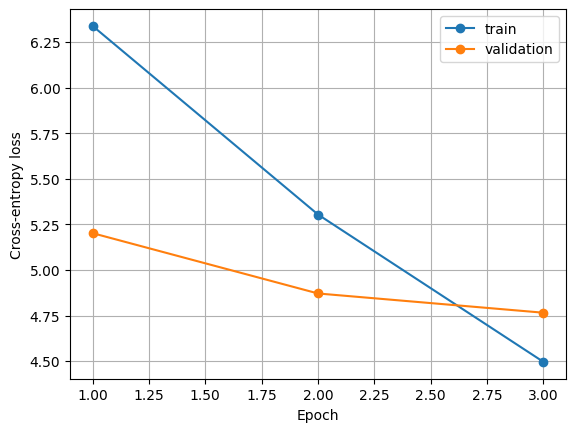

In [8]:
hist = pd.DataFrame(history)
plt.plot(hist.epoch, hist.train_loss, marker="o", label="train")
plt.plot(hist.epoch, hist.val_loss, marker="o", label="validation")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss"); plt.legend(); plt.grid(True); plt.show()

## 6. Scratch-model decoding and attention visualization

In [9]:
checkpoint = torch.load("artifacts/gru_bahdanau.pt", map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model"])
model.eval()

def decode_scratch(sentence, return_attention=False):
    src = torch.tensor([encode(sentence,src_stoi)], device=DEVICE)
    with torch.no_grad():
        enc_out, hidden = model.encoder(src)
        mask = src.ne(PAD)
        token = torch.tensor([SOS], device=DEVICE)
        out_ids, attn_rows = [], []
        for _ in range(MAX_LEN):
            logits, hidden, weights = model.decoder.forward_step(token, hidden, enc_out, mask)
            nxt = logits.argmax(-1)
            idx = int(nxt.item())
            if return_attention: attn_rows.append(weights.squeeze(0).cpu().numpy())
            if idx == EOS: break
            out_ids.append(idx); token = nxt
    words = [tgt_itos[i] if i < len(tgt_itos) else "<unk>" for i in out_ids]
    result = " ".join(words)
    return (result, np.array(attn_rows)) if return_attention else result

for s,t in test_pairs[:5]:
    print("EN:",s,"\nREF:",t,"\nGRU:",decode_scratch(s),"\n")

EN: In the Rs. 
REF: పంథాలో ఏడాదికి కాలంలో రూ. 
GRU: <unk> <unk> <unk> <unk> <unk> <unk> 

EN: In the third phase, 69 assembly seats spread over 12 districts will go to polls. 
REF: ఈ దశలో 12 జిల్లాల్లోని 69 నియోజక వర్గాలకు పోలింగ్‌ నిర్వహించనున్నారు. 
GRU: <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> 

EN: BSE Midcap and Smallcap indices shed 0.4 per cent each. 
REF: బీఎస్‌ఈలో మిడ్‌, స్మాల్‌క్యాప్‌ ఇండెక్సులు 0.4 శాతం చొప్పున నీరసించాయి. 
GRU: <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> 

EN: (He has gone mad. 
REF: (అంటూ విసుక్కుని వెళ్లిపోయాడు. 
GRU: <unk> <unk> <unk> <unk> 

EN: By virtue... 
REF: అద్వానంగా . 
GRU: <unk> <unk> <unk> 



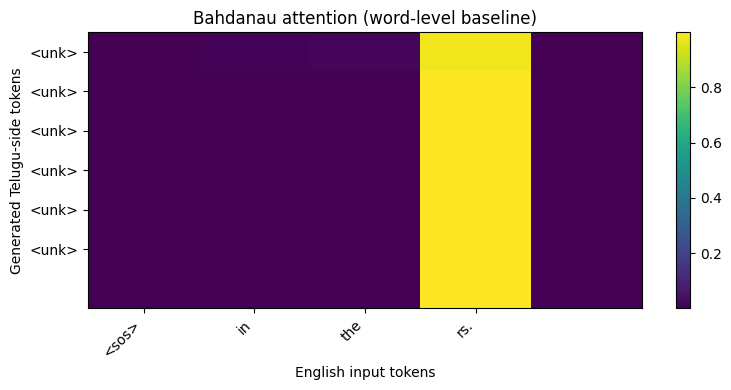

In [10]:
sample_src = test_pairs[0][0]
prediction, attention = decode_scratch(sample_src, return_attention=True)
src_tokens = ["<sos>"] + tokenize(sample_src)[:MAX_LEN]
pred_tokens = prediction.split()
if attention.size:
    plt.figure(figsize=(max(8,len(src_tokens)*0.6), max(4,len(pred_tokens)*0.45)))
    plt.imshow(attention, aspect="auto")
    plt.xticks(range(len(src_tokens)), src_tokens, rotation=45, ha="right")
    plt.yticks(range(len(pred_tokens)), pred_tokens)
    plt.xlabel("English input tokens"); plt.ylabel("Generated Telugu-side tokens")
    plt.title("Bahdanau attention (word-level baseline)")
    plt.colorbar(); plt.tight_layout(); plt.show()

## 7. Evaluate scratch model with BLEU and chrF

In [11]:
EVAL_N = min(300, len(test_pairs))
eval_pairs = test_pairs[:EVAL_N]
references = [t for s,t in eval_pairs]
scratch_hypotheses = [decode_scratch(s) for s,t in eval_pairs]
scratch_bleu = sacrebleu.corpus_bleu(scratch_hypotheses, [references])
scratch_chrf = sacrebleu.corpus_chrf(scratch_hypotheses, [references])
print("Scratch BLEU:", scratch_bleu.score)
print("Scratch chrF:", scratch_chrf.score)

Scratch BLEU: 0.14049375407910675
Scratch chrF: 4.8744936436827615


## 8. Evaluate pretrained NLLB-200 distilled 600M
NLLB is a strong pretrained baseline, not fine-tuned on this project subset. Its model card uses `eng_Latn` for English and supports `tel_Telu` for Telugu. Model weights are large; allow time and GPU memory for download and inference.

In [12]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

NLLB_ID = "facebook/nllb-200-distilled-600M"
nllb_tokenizer = AutoTokenizer.from_pretrained(NLLB_ID, src_lang="eng_Latn")
nllb_model = AutoModelForSeq2SeqLM.from_pretrained(NLLB_ID).to(DEVICE)
nllb_model.eval()
telugu_id = nllb_tokenizer.convert_tokens_to_ids("tel_Telu")

def translate_nllb(texts, batch_size=8):
    outputs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        inputs = nllb_tokenizer(batch, return_tensors="pt", padding=True,
                                truncation=True, max_length=128).to(DEVICE)
        with torch.no_grad():
            generated = nllb_model.generate(**inputs, forced_bos_token_id=telugu_id,
                                            max_new_tokens=128, num_beams=4)
        outputs.extend(nllb_tokenizer.batch_decode(generated, skip_special_tokens=True))
    return outputs

nllb_hypotheses = translate_nllb([s for s,t in eval_pairs])
nllb_bleu = sacrebleu.corpus_bleu(nllb_hypotheses, [references])
nllb_chrf = sacrebleu.corpus_chrf(nllb_hypotheses, [references])
print("NLLB BLEU:", nllb_bleu.score)
print("NLLB chrF:", nllb_chrf.score)

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (5 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

NLLB BLEU: 8.281615274672166
NLLB chrF: 40.36902805234318


## 9. Side-by-side comparison and error analysis

In [13]:
results = pd.DataFrame({
    "Model":["GRU + Bahdanau (from scratch)","NLLB-200 distilled 600M"],
    "BLEU":[scratch_bleu.score,nllb_bleu.score],
    "chrF":[scratch_chrf.score,nllb_chrf.score]
})
display(results)
display(pd.DataFrame({
    "English":[s for s,t in eval_pairs[:20]],
    "Reference Telugu":[t for s,t in eval_pairs[:20]],
    "Scratch GRU":[x for x in scratch_hypotheses[:20]],
    "NLLB":[x for x in nllb_hypotheses[:20]]
}))

,Model,BLEU,chrF
0,GRU + Bahdanau (from scratch),0.140494,4.874494
1,NLLB-200 distilled 600M,8.281615,40.369028


,English,Reference Telugu,Scratch GRU,NLLB
0,In the Rs.,పంథాలో ఏడాదికి కాలంలో రూ.,<unk> <unk> <unk> <unk> <unk> <unk>,రూ.
1,"In the third phase, 69 assembly seats spread o...",ఈ దశలో 12 జిల్లాల్లోని 69 నియోజక వర్గాలకు పోలి...,<unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk...,మూడో దశలో 12 జిల్లాల్లో 69 అసెంబ్లీ సీట్లు పోల...
2,BSE Midcap and Smallcap indices shed 0.4 per c...,"బీఎస్‌ఈలో మిడ్‌, స్మాల్‌క్యాప్‌ ఇండెక్సులు 0.4...",<unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk...,"BSE మిడ్ క్యాప్, స్మాల్ క్యాప్ సూచికలు 0.4% తగ..."
3,(He has gone mad.,(అంటూ విసుక్కుని వెళ్లిపోయాడు.,<unk> <unk> <unk> <unk>,(అతను వెర్రి మారింది.
4,By virtue...,అద్వానంగా .,<unk> <unk> <unk>,ధర్మశాస్త్రం ద్వారా.
5,I stared at the squirrel.,విసుగ్గా వాచీ కేసి చూసుకున్నాను.,<unk> <unk> <unk> <unk>,నేను ఎద్దును చూసాను.
6,Last date to apply: April 24,దరఖాస్తులకు చివరితేదీ :24 ఏప్రిల్ 2019,గత 24 గంటల్లో <unk> <unk> <unk> <unk> <unk> <u...,దరఖాస్తుకు చివరి తేదీః ఏప్రిల్ 24
7,Working with new directors.,కొత్త దర్శకులతో పనిచేయాలని కోరుకుంటున్నాను.,కొత్త కొత్త <unk>,కొత్త దర్శకులతో పని.
8,Lalu Yadav had recently undergone a fistula op...,ఇటీవలనే ముంబాయి ఆసుపత్రిలో లాలూజీ ఫిస్టులా ఆపర...,<unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk...,లాలూ యాదవ్ ఇటీవల ముంబై ఆసుపత్రిలో ఫిస్టల్ ఆపరే...
9,However these factors have not stopped it beco...,"అయినప్పటికీ, దీని ప్రభావము మనమీద తెలియదు ఇంకా ...",ఈ <unk> <unk> <unk> <unk> <unk> కాదు.,"అయితే, ఈ కారణాల వల్ల ఇది ప్రజాదరణ పొందింది."


## 10. Save artifacts for the Streamlit app
Download the scratch checkpoint and vocabularies. NLLB can be downloaded by the app environment on first run, or stored separately if deployment storage permits. Do not commit huge model weights to GitHub; use Git LFS or a model hosting service if needed.

In [14]:
import pickle
with open("artifacts/vocabularies.pkl","wb") as f:
    pickle.dump({"src_stoi":src_stoi,"src_itos":src_itos,
                 "tgt_stoi":tgt_stoi,"tgt_itos":tgt_itos}, f)
pd.DataFrame(results).to_csv("artifacts/evaluation_metrics.csv", index=False)
with open("artifacts/sample_predictions.json","w",encoding="utf-8") as f:
    json.dump([{"english":s,"reference":t,"scratch":g,"nllb":n}
               for (s,t),g,n in zip(eval_pairs,scratch_hypotheses,nllb_hypotheses)],
              f,ensure_ascii=False,indent=2)
print("Saved artifacts:", os.listdir("artifacts"))

Saved artifacts: ['gru_bahdanau.pt', 'evaluation_metrics.csv', 'vocabularies.pkl', 'sample_predictions.json']


## Notes / limitations
- The scratch model uses a simple word-level vocabulary and a small sample. Expect unknown words and weaker fluency than NLLB.
- Samanantar's dataset card specifies **CC-BY-NC 4.0**. Check the license and model terms before commercial use.
- BLEU/chrF scores depend on the exact test subset, tokenization, and normalization. Report the evaluation sample size and settings.
- For a stronger experiment: increase training pairs, use SentencePiece subwords, train longer with early stopping, and evaluate on a held-out benchmark such as FLORES-200 Telugu.
- Keep the test set separate from training. Avoid selecting the test examples from the training subset.